In [1]:
!pip install micrograd

In [3]:
from micrograd.engine import Value
a = Value(-4.0)
b = Value(2.0)


In [ ]:
c = a+b
d = a*b+b**3
c+=c+1
c+=1 + c + (-a)
d += d *2 + (b+a).relu()
d += d*2 +(b-a).relu()
e = c - d
f = e**2
g = f/2.0
g += 10.0/f
# g.data:.4f this will print g value gotten from the fwd pass
print(f'{g.data:.4f}')
g.backward()
print(f'{a.grad:.4f}')
print(f'{a.grad:.4f}')

In [12]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
def f(x):
    return 3*x**2 - 4*x + 5  # just a function that takes single scaler x and returns single scaler y

In [5]:
f(3.0)

20.0

In [7]:
xs = np.arange(-5,5,0.25)
ys = f(xs)
ys

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

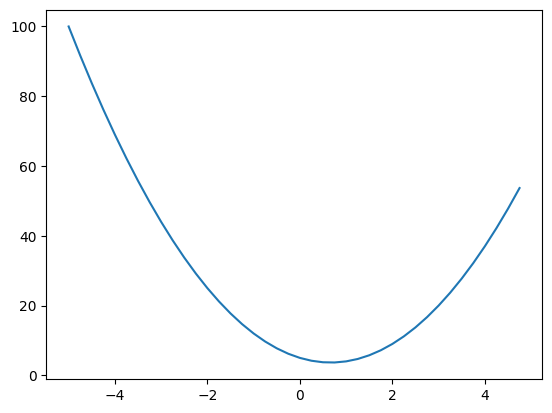

In [8]:
plt.plot(xs,ys)


**-with what sensitivity or how does the function respond due to a small change h
; f(x+h)-f(x) is the change , and by "how much"is the strength of that slope**


In [10]:
h = 0.0000001
x = 2/3
(f(x+h)-f(x))/h


2.9753977059954195e-07

In [12]:
# lets get more complex
# d is output , fucntion of 3 scaler

a = 2.0
b = -3.0
c = 10.0
d = a*b + c 
print(d)

4.0


In [13]:
h = 0.0001
# we will choose an input point to find the derivative at
a = 2.0
b = -3.0
c = 10.0
d1 = a*b + c 
# since we need der. about a
a += h
d2 = a*b + c 
print('d1', d1)
print('d2', d2)
print('slope',(d2-d1)/h)

d1 4.0
d2 3.999699999999999
slope -3.000000000010772


In [14]:
h = 0.0001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
c += h
d2 = a*b + c

print('d1', d1)
print('d2', d2)
print('slope', (d2 - d1)/h)
# since c is the constant, an infintesimal change in c will lead to the exact same change in d

d1 4.0
d2 4.0001
slope 0.9999999999976694


**its derivative is the rate at which d will increase as we scale c**

In [8]:
# we need to build this data structures to build these neural networks

# Building 'value'obj.

class Value: # stores a single scalar value and its gradient- other things we built on the way
    def __init__(self,data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)  # prolly for efficiency
        self._op = _op
        self._backward = lambda: None
        self.label = label
        self.grad = 0.0
    def __repr__(self):
        return f"Value(data={self.data})"
    def __add__(self,other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward

        return out
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        
        return out
    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += (other * self.data**(other-1)) * out.grad
        out._backward = _backward

        return out
    def relu(self):
        out = Value(0 if self.data < 0 else self.data, (self,), 'ReLU')

        def _backward():
            self.grad += (out.data > 0) * out.grad
        out._backward = _backward

        return out
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self,), 'tanh')
        
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        
        return out
    def exp(self):
        x = self.data
        t = math.exp(x)
        out = Value(t, (self,), 'exp')
        
        def _backward():
            self.grad += t * out.grad
        out._backward = _backward
        
        return out
    def backward(self):
        
        # build the topological ordered list of all the children in the DAG
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
 
        # We must go through the topogical ordered list in the reverse order as per backpropagation
        # We must go through one variable at a time and
        # then apply the chain rule to get its gradient
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()
    def __neg__(self): # -self
        return self * -1

    def __radd__(self, other): # other + self
        return self + other

    def __sub__(self, other): # self - other
        return self + (-other)

    def __rsub__(self, other): # other - self
        return other + (-self)

    def __rmul__(self, other): # other * self
        return self * other

    def __truediv__(self, other): # self / other
        return self * other**-1

    def __rtruediv__(self, other): # other / self
        return other * self**-1

a = Value(2.0, label = 'a')
b = Value(-3.0, label = 'b')
c = Value(10.0, label = 'c')
#d = a *b+c # internally a.__mul__(b).__add__(c)
e = a*b; e.label = 'e'
d = e+c; d.label = 'd'
f = Value(-2.0, label='f')
L = d*f; L.label = 'L'
L

Value(data=-8.0)

In [4]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [5]:
d._op

'+'

In [7]:
import graphviz
graphviz.__version__, graphviz.version()

('0.21', (2, 43, 0))

In [9]:
from graphviz import Digraph

def trace(root):
    """
    builds a set of all nodes and edges in a graph
    """
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
    nodes, edges = trace(root)    
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph,create a rectangular ('record') node for it
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name = uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)
    
    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot

L = d*f 
dL/dd = ? f
(f(x+h)-f(x))/h
((d+h)*f-d*f)/h
(d*f+h*f - d*f) / h
(h*f) / h
f

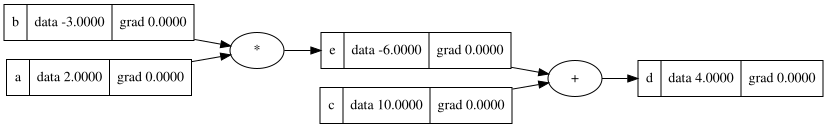

In [10]:
draw_dot(d)

In [2]:
def lol(): # like an in-line gradient check
    h = 0.0001
    a = Value(2.0, label = 'a')
    b = Value(-3.0, label = 'b')
    c = Value(10.0, label = 'c')
    #d = a *b+c # internally a.__mul__(b).__add__(c)
    e = a*b; e.label = 'e'
    d = e+c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d*f; L.label = 'L'
    L1 = L.data

    a = Value(2.0 + h, label = 'a') # here we are adding h to a , so we are nudging 'a', and so this finding gradient wrt to a
    b = Value(-3.0, label = 'b')
    c = Value(10.0, label = 'c')
    #d = a *b+c # internally a.__mul__(b).__add__(c)
    e = a*b; e.label = 'e'
    d = e+c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d*f; L.label = 'L'
    L2 = L.data

    print((L2-L1)/h)

lol()
# weirdly, if you change L by h , you get one , cause this change is exactly proportional 

6.000000000021544


we know how c impacts d; and how d impacts L 
so we do know that somehow we can find how c impacts L

In [3]:
# from manual calc
L.grad = 1
f.grad = 4.0
d.grad = -2.0
c.grad = -2
e.grad = -2
a.grad = -2.0*-3.0
b.grad = -2.0*2.0

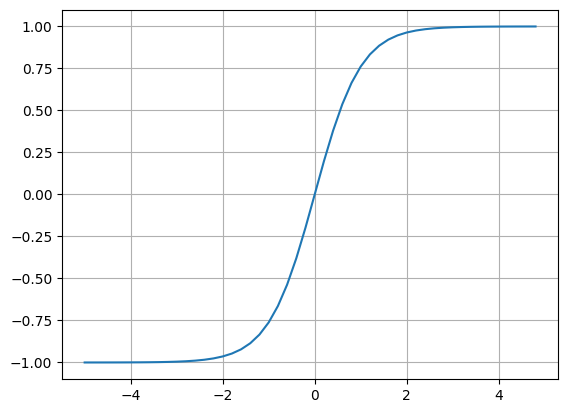

In [7]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid();
# activation functions do this job of squishing the inputs

In [8]:
# preview of single optimization step
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad # cause we are adding gradients , loss is expected in increase

e = a * b 
d = e + c
L = d * f

print(L.data)

-7.286496


In [14]:
# inputs x1,x2
x1 = Value(2.0,label='x1')
x2 = Value(0.0,label='x2')
# weights w1, w2
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
# bias of the neuron
b = Value(6.8813735870195432,label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label ='x1w1'
x2w2 = x2*w2; x2w2.label ='x2w2'
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.label='x1w1 + x2w2'
n = x1w1x2w2+b; n.label='n'
o = n.tanh(); o.label = 'o'


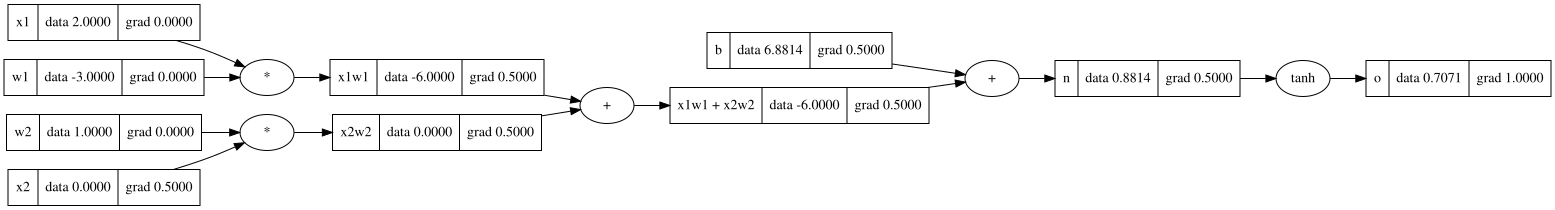

In [16]:
draw_dot(o)

In [15]:
n.grad = 0.5  # do/dn= i-o**2 ; because tanh(n)=o
o.grad = 1.0
x1w1x2w2.grad = 0.5
b.grad = 0.5
x1w1.grad = 0.5 # a '+' just passes th gradients
x2w2.grad = 0.5

x2.grad = x2w2.grad * w2.data
w2.grad = x2w2.grad * x2.data

The level at which you would want to implement your backward pass is upto you.
You can even implement it for tiny +, - and stuff or higher level function entities.
We just need to find the local gradient of this composite function( and mul with all the aage ka grad we found near the child which would already be ready due to topo check), where output is the function of inputs in someway

In [17]:
# inputs x1,x2
x1 = Value(2.0,label='x1')
x2 = Value(0.0,label='x2')
# weights w1, w2
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
# bias of the neuron
b = Value(6.8813735870195432,label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label ='x1w1'
x2w2 = x2*w2; x2w2.label ='x2w2'
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.label='x1w1 + x2w2'
n = x1w1x2w2+b; n.label='n'
o = n.tanh() 
o.label = 'o'

In [18]:
o.grad = 1.0           #do/do (initialize to 1: agrees with the derivative too)

o._backward()          #do/dn
n._backward()          #do/db = do/d(x1w1+x2w2)
b._backward()          #b is a leaf node, so it does not have a _backward() function
x1w1x2w2._backward()   #do/d(x1w1) = do/d(x2w2)
x2w2._backward()       #do/d(x2), do/d(w2)
x1w1._backward()       #do/d(x1), do/d(w1)
#x1, w1, x2, w2 are leaf nodes, therefore they don't have _backward() functions

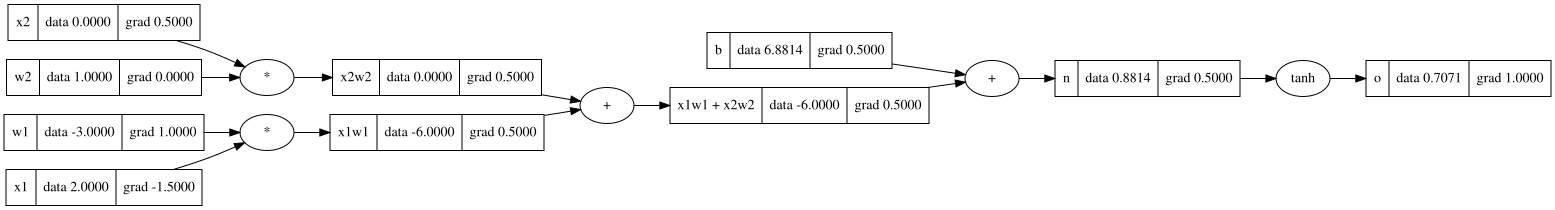

In [19]:
draw_dot(o)

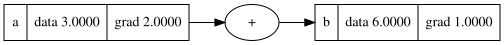

In [20]:
# Fixing backprop bug when - one node is used multiple times
a = Value(3.0, label = 'a')
b = a + a ; b.label ='b'
b.backward()
draw_dot(b)

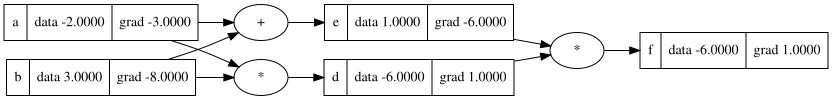

In [21]:
a = Value(-2.0,label='a')
b = Value(3.0,label='b')


d = a * b   ; d.label ='d'
e = a + b   ; e.label = 'e'
f = d * e   ; f.label='f'

f.backward()

draw_dot(f)

**According to multivariate chain rule, we'd just need to accumulate the gradients**, so we added += everywhere in the value class

**Breaking up tanh into its fine atomic parts**

In [22]:
# inputs x1,x2
x1 = Value(2.0,label='x1')
x2 = Value(0.0,label='x2')
# weights w1, w2
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
# bias of the neuron
b = Value(6.8813735870195432,label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label ='x1w1'
x2w2 = x2*w2; x2w2.label ='x2w2'
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.label='x1w1 + x2w2'
n = x1w1x2w2+b; n.label='n'
# -----------
e = (2*n).exp()
o = (e - 1)/(e + 1)
# ------------
o.label = 'o'
o.backward()

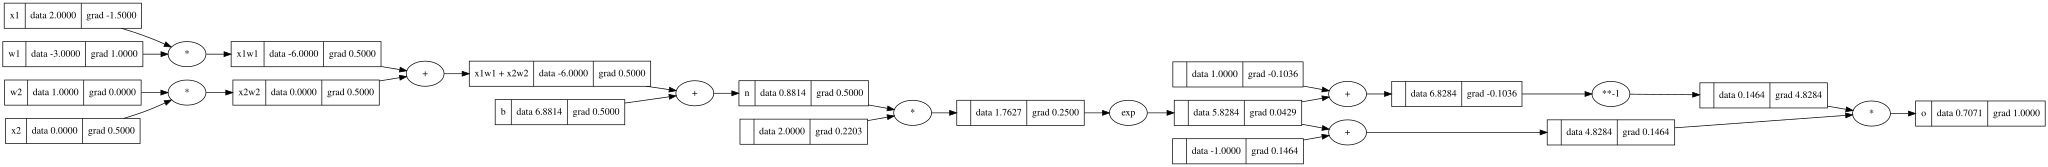

In [23]:
draw_dot(o)

In [2]:
# Trying with PyTorch API - verifying
import sys
print(sys.executable)
import torch

/usr/bin/python3


In [3]:
torch.Tensor([[1, 2, 3], [4, 5, 6]]),\
torch.Tensor([[1, 2, 3], [4, 5, 6]]).shape

(tensor([[1., 2., 3.],
         [4., 5., 6.]]),
 torch.Size([2, 3]))

In [4]:
torch.tensor([2.0]).dtype,\
torch.tensor([2.0]).double().dtype # casting to double to match with python's stuff

(torch.float32, torch.float64)

In [5]:
x1 = torch.tensor([2.0]).double()     ;x1.requires_grad=True
w1 = torch.tensor([-3.0]).double()    ;w1.requires_grad=True
x2 = torch.tensor([0.0]).double()     ;x2.requires_grad=True
w2 = torch.tensor([1.0]).double()     ;w2.requires_grad=True
b  = torch.tensor([6.8813735870195432]).double()     ;b.requires_grad=True
n = w1*x1 + w2*x2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('-----')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
-----
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [6]:
o, o.item(), o.data.item() # item() to only get the tensor

(tensor([0.7071], dtype=torch.float64, grad_fn=<TanhBackward0>),
 0.7071066904050358,
 0.7071066904050358)